In [1]:
import pandas as pd
df = pd.read_csv("/content/lizard_data.csv")

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


# İlk 5 satırı gösterme
display(df.head())

,Tur,Cinsiyet,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu,YasamAlani
0,Uta,Disi,43.8,102.2,5.18,21.6,Yer
1,Sceloporus,Disi,62.1,149.8,16.78,29.7,Kaya
2,Uta,Disi,37.6,76.4,4.94,18.5,Yer
3,Sceloporus,Erkek,70.4,170.4,18.23,28.4,Yer
4,Anolis,Disi,52.7,137.9,8.60,25.8,Agac


Şimdi veri setinin genel yapısına, sütun bilgilerine ve temel istatistiklerine bakalım.

In [3]:
print('Satır sayısı:', df.shape[0])
print('Sütun sayısı:', df.shape[1])
print()
print('Sütun isimleri:')
print(df.columns.tolist())



Satır sayısı: 320
Sütun sayısı: 7

Sütun isimleri:
['Tur', 'Cinsiyet', 'GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'YasamAlani']


In [4]:
#her sınıftan kaç tane var?
print('\nYasamAlani dağılımı:')
print(df['YasamAlani'].value_counts())




YasamAlani dağılımı:
YasamAlani
Yer     151
Kaya     96
Agac     73
Name: count, dtype: int64


In [5]:
print('\nSayısal özet istatistikleri:')
display(df.describe().round(1))


Sayısal özet istatistikleri:


,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu
count,320.0,320.0,320.0,320.0
mean,60.8,145.1,12.5,27.3
std,10.5,26.1,5.7,5.7
min,36.4,76.4,2.6,13.8
25%,52.7,124.4,8.2,22.8
50%,59.8,141.8,10.5,27.2
75%,69.6,166.2,17.4,31.0
max,83.3,209.4,25.9,43.9


**Veri kümesinde kaç kertenkele var?** cevap: 320
**Hangi yaşam alanı en kalabalık? **cevap: yer
 **Hangisi en az?** cevap:ağaç
**Bu dengesizlik modelimizi nasıl etkileyebilir?** cevap: Veri dengesizliği, modelin baskın sınıfa odaklanmasına yol açar;cevap: bu nedenle çoğunluk sınıfını başarılı bir şekilde öğrenirken azınlık sınıfında düşük performans gösterebilir.

**Kertenkelelerin ortalama ağırlığı nedir?** cevap: 10.50
**Bu değer üç tür için farklı mıdır? Nedenini açıklayın.**
cevap: Evet farklıdır. Çünk farklı kertenkele türleri, farklı yaşam alanlarına uyum sağlamıştır.

In [6]:
hedef_degisken = 'YasamAlani'
ozellikler = [col for col in df.columns if col != hedef_degisken]

# Hedef değişken (y)
y = df[hedef_degisken]

X = pd.get_dummies(df[ozellikler], drop_first=True)



In [7]:
print(f'Hedef Değişken: {hedef_degisken}')
print(f'Özellik Sütunları (one-hot encoding sonrası): {X.columns.tolist()}')
display(X.head())

Hedef Değişken: YasamAlani
Özellik Sütunları (one-hot encoding sonrası): ['GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'Tur_Sceloporus', 'Tur_Uta', 'Cinsiyet_Erkek']


,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu,Tur_Sceloporus,Tur_Uta,Cinsiyet_Erkek
0,43.8,102.2,5.18,21.6,False,True,False
1,62.1,149.8,16.78,29.7,True,False,False
2,37.6,76.4,4.94,18.5,False,True,False
3,70.4,170.4,18.23,28.4,True,False,True
4,52.7,137.9,8.60,25.8,False,False,False


In [8]:
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y)



**stratify=y parametresini kaldırırsanız ne değişebilir? Deneyin ve farkı açıklayın.** cevap:stratify=y kullanıldığında sınıfların oranı eğitim ve test verilerinde korunur. Bu parametreyi kaldırdığımda bazı sınıfların eğitim veya test verisinde daha az yer aldığını gördüm. Bu da modelin başarısını etkileyebilir ve sonuçların daha dengesiz olmasına neden olabilir.

**random_state=42 yerine random_state=7 yazarsanız sonuçlar değişir mi? Deneyin ve nedenini açıklayın.**
 cevap: Evet, sonuçlar değişebilir. Çünkü random_state verilerin nasıl bölüneceğini belirler. Farklı bir değer kullanıldığında eğitim ve test kümelerine giden veriler değişir. Bu nedenle modelin doğruluk oranı ve oluşturduğu karar ağacı da biraz farklı olabilir. Ancak veri seti büyükse bu fark genellikle çok fazla olmaz.

In [9]:
print('Eğitim seti:', len(X_egitim), 'kertenkele')
print('Test seti:  ', len(X_test),   'kertenkele')
print()
print('Eğitim seti sınıf dağılımı:')
print(y_egitim.value_counts())
print('\nTest seti sınıf dağılımı:')
print(y_test.value_counts())

Eğitim seti: 256 kertenkele
Test seti:   64 kertenkele

Eğitim seti sınıf dağılımı:
YasamAlani
Yer     121
Kaya     77
Agac     58
Name: count, dtype: int64

Test seti sınıf dağılımı:
YasamAlani
Yer     30
Kaya    19
Agac    15
Name: count, dtype: int64


In [10]:
derinlikler = list(range(1, 11))

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim, y_egitim)

    egitim_mcr = 1 - accuracy_score(y_egitim, agac.predict(X_egitim))
    test_mcr = 1 - accuracy_score(y_test, agac.predict(X_test))

    print(f"{derinlik:>10} {egitim_mcr:>12.3f} {test_mcr:>10.3f}")

         1        0.488      0.484
         2        0.359      0.312
         3        0.352      0.328
         4        0.324      0.328
         5        0.285      0.438
         6        0.242      0.438
         7        0.156      0.438
         8        0.129      0.469
         9        0.066      0.484
        10        0.051      0.484


**1)Çıktıya bakarak eğitim ve test hatasının derinlik arttıkça nasıl değişmektedir? Eğitim ve test değerlerine bakarak gerekçenizi yazın.**

cevap: Derinlik arttıkça; eğitim hatası sürekli azalırken, biyere kadar azalıp ardından tekrar artışa geçmektedir.

**2)Eğitim hatası sıfıra yaklaşıyorsa bu modelin "mükemmel" öğrendiği anlamına gelir mi? Sizce ne anlama geliyor?**

Derinliğe ulaşıldığı anda karar ağacı modeli artık verideki genel yapıyı öğrenmekten çıkıp overfitting yapmaya, yani ezberlemeye geçmiştir. Mükemmel öğrendiği anlama gelmez.

**3)Hangi derinlikte eğitim hatası düşmeye devam ederken test hatası artmaya başladı? O satırda modele ne olduğunu açıklayın.** 2. satırda derinliğe ulaşıldığı anda karar ağacı modeli artık verideki genel yapıyı öğrenmeyi bırakıp overfitting sürecine geçmiştir.

Bunun sonucunda model eğitim verisine aşırı uyum sağladığı için eğitim hatası düşerken, genelleme yeteneğini kaybetmiş ve ilk kez gördüğü test verilerinde daha fazla hata yapmaya başlayarak test hatasını artırmıştır.



**4)Yalnızca bu sayılara bakarak hangi derinliği seçerdiniz? Hem eğitim hem test hatasını göz önünde bulundurarak gerekçenizi yazın.** cevap: derinlik 2 , genel kuralları en iyi öğrendiği ve test setinde en yüksek performansı gösterdiği en güvenli ve en ideal noktadır.

**5)En düşük test hatası (MCR) ile en düşük eğitim hatası farklı derinliklerde mi çıktı? Bu size ne söylüyor?**
Evet, çünkü model ezberleme kapasitesinin en üst seviyesine çıktığında eğitim hatası en düşük seviyeye iner; ancak bu ezber yeni verileri genelleştiremediği için test hatası yükselir. Bu nedenle makine öğrenmesinde eğitim ve test performansı genellikle aynı derinlikte en iyi sonucu vermez.

In [11]:
egitim_mcr = []
test_mcr = []



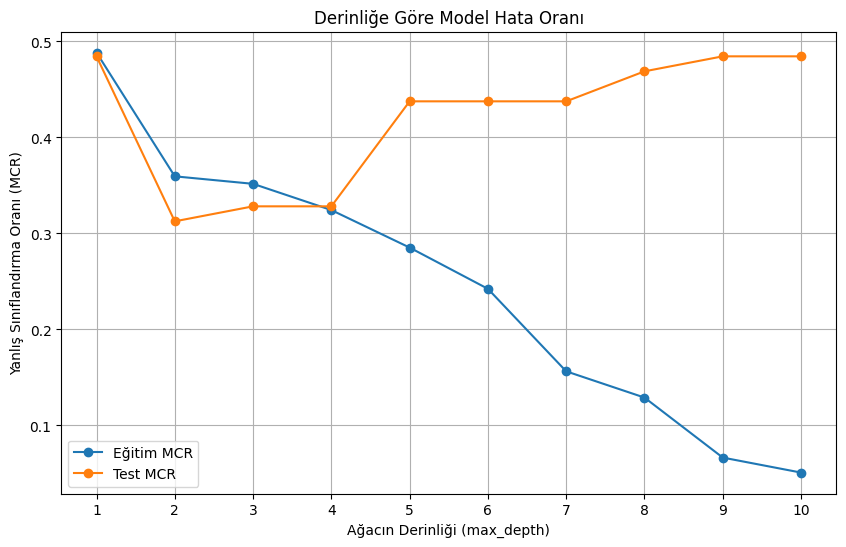

In [12]:
for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim,y_egitim)
    egitim_mcr.append(1 - accuracy_score(y_egitim, agac.predict(X_egitim)))
    test_mcr.append(  1 - accuracy_score(y_test,agac.predict(X_test)))

plt.figure(figsize=(10, 6))
plt.plot(derinlikler, egitim_mcr, marker='o', label='Eğitim MCR')
plt.plot(derinlikler, test_mcr, marker='o', label='Test MCR')
plt.xlabel('Ağacın Derinliği (max_depth)')
plt.ylabel('Yanlış Sınıflandırma Oranı (MCR)')
plt.title('Derinliğe Göre Model Hata Oranı')
plt.legend()
plt.grid(True)
plt.xticks(derinlikler) # x ekseninde tüm derinlikleri gösterir
plt.show()

**1)Grafikteki iki eğri birbirinden ne zaman ayrılmaya başlıyor? Bu ayrılma noktası size ne söylüyor?**

Grafiği incelediğimizde, 4⁠ noktasında eğitim ve test hatasının birbirine oldukça yakın olduğunu, 5⁠ itibarıyla aradaki boşluğun belirginleşerek açılmaya başladığını görüyoruz. Bu bize ne söylüyor: Ayrılma noktası, modelin eğitim verisini ezberlemeye başladığı "eşik değerini" gösterir. 5. seviyeden sonra model, eğitim verisindeki gürültüleri de öğrenmeye başladığı için test setindeki başarımı düşmeye veya durağanlaşmaya başlarken, eğitim setindeki başarısı artmaya devam ediyor.

**2)Eğitim ve test eğrileri arasındaki mesafe derinlikle birlikte açılıyorsa buna ne ad verilir?** Eğitim hatası düşerken (model ezberledikçe) test hatasının sabit kalması veya artmasıyla oluşan bu duruma Aşırı Öğrenme (Overfitting) denir. Model, eğitim verisine o kadar uyumlu hale gelir ki, daha önce görmediği test verisine genelleme yapma yeteneğini kaybeder.

**3)Grafiğe bakarak hangi max_depth değerini seçerdiniz? Sayısal tablodaki kararınızla aynı mı? **cevap: Grafiğe baktığımızda, ⁠max_depth = 4⁠ noktası kritik bir dönüm noktasıdır. Bu noktadan sonra test hatası  iyileşmeyi durdurup yatay seyrederken veya hafifçe artarken, eğitim hatası hızla düşmektedir.  Eğer test hatasının minimum olduğu noktayı hedefliyorsak, 4 değeri en ideal noktadır. Çünkü 4'den sonra derinliği artırmak modelin karmaşıklığını artırır ancak test başarısını iyileştirmez; bu da gereksiz karmaşıklığa yol açar. Sayısal tabloyu göremiyorum ancak genellikle bu tip grafiklerde en düşük test hatası 3 ile 4 arasında gözlemlenir. Aynı çıktı.

**4)Kurduğunuz her karar ağacı için bu grafiği ayrı ayrı çizin. Optimum derinlik her hedef için aynı mı çıktı? Farklılaştıysa neden?** (son grafiğin arkasında cevaplanacaktır)

In [13]:
optimum_derinlik = 4

final_agac = DecisionTreeClassifier(max_depth=optimum_derinlik, random_state=42)
final_agac.fit(X_egitim, y_egitim)




DecisionTreeClassifier(max_depth=4, random_state=42)

In [14]:
y_tahmin = final_agac.predict(X_test)
test_mcr = 1 - accuracy_score(y_test, y_tahmin)
print(f'Optimum Derinlik: {optimum_derinlik}')
print(f'Test Hatası (MCR): {test_mcr:.4f}')

Optimum Derinlik: 4
Test Hatası (MCR): 0.3281


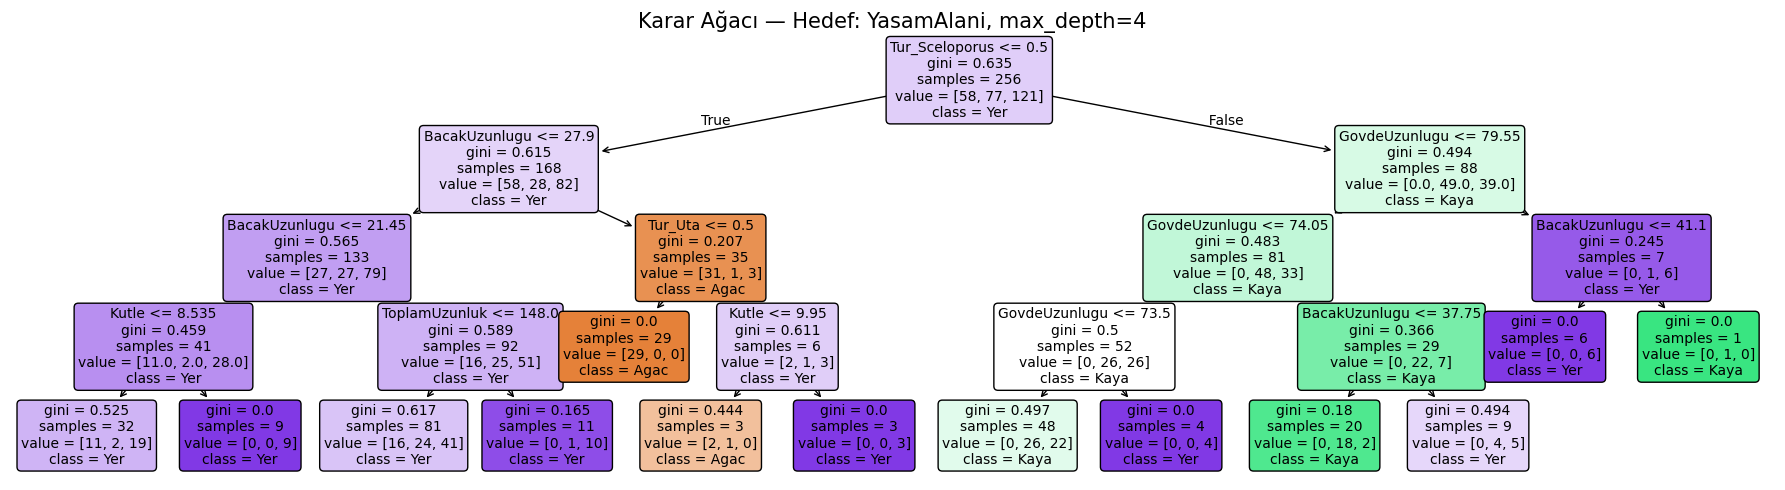

In [15]:
plt.figure(figsize=(18, 5))
plot_tree(
    final_agac,
    feature_names=X.columns.tolist(),
    class_names=list(final_agac.classes_.astype(str)), # sınıf isimlerini metne çevirir
    filled=True,
    rounded=True,
    fontsize=10 # Yazı boyutunu ayarlandı
)
plt.title(f'Karar Ağacı — Hedef: {hedef_degisken}, max_depth={optimum_derinlik}', fontsize=15)
plt.tight_layout()
plt.show()

Ağacı yorumlama soruları:
 **1)Kök düğümde hangi değişken kullanılmış? Neden tam da bu değişkenin ilk sırada yer aldığını düşünüyorsunuz? cevap:** Değişken: Kök düğümde "cinsiyet" değişkeni kullanılmış. Neden: Karar ağacı algoritmaları , veriyi sınıflara en iyi ayıracak (en saf hale getirecek) değişkeni seçer. "cinsiyet", veri setindeki "Yer", "Kaya" ve "Agac" sınıflarını birbirinden ayırma konusunda en yüksek bilgi kazancını sağladığı için en tepede yer alır. Bu, ağacın "en ayırt edici" özelliğinin cinsiyet olduğunu gösterir.


  **2)Ağaç yapraktan köke doğru okunduğunda bir kertenkeleyi sınıflandırmak için kaç karar yeterli oluyor? Bu sayı size ne söylüyor?**

cevap: Grafiğe baktığımızda, herhangi bir yaprağa ulaşmak için kök düğümden sonra en az 3 en fazla 4 dal daha takip etmemiz gerekiyor. Yani toplam 4 karar bir kertenkeleyi sınıflandırmak için yeterli oluyor. Bu, modelin çok karmaşık olmayan, hızlı ve verimli bir sınıflandırma yaptığını gösterir.

**3)Aynı veri, farklı bir hedef değişkenle (örneğin YasamAlani yerine Tur) çalıştırıldığında kök düğüm değişti mi? Değiştiyse bunu nasıl yorumlarsınız? Son hedef değişkenden sonra cevaplanacaktır.**

cevap: Evet, kök düğüm değişecektir. Makine öğrenmesinde değişkenlerin önemi, hedef değişkenle olan ilişkilerine göre belirlenir. Eğer hedef değişkeni "YaşamAlanı"ndan "Tür"e çevirirseniz, verideki "Tür" bilgisini en iyi ayıran özellik (örneğin belki Bacak Uzunluğu veya Gövde Uzunluğu) "Kütle"den daha baskın hale gelebilir. Hedef değiştiğinde, ağacın "sınıflandırma kriterleri" yeniden hesaplanır ve ağaç yapısı buna göre şekillenir.

---


İkinci karar ağacımızı `Cinsiyet` hedef değişkeni

In [16]:
# Hedef değişkeni ve özelliklerin tanımlanması
hedef_degisken = 'Cinsiyet'
ozellikler = [col for col in df.columns if col != hedef_degisken]


y = df[hedef_degisken]


X = pd.get_dummies(df[ozellikler], drop_first=True)

display(X.head())

,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu,Tur_Sceloporus,Tur_Uta,YasamAlani_Kaya,YasamAlani_Yer
0,43.8,102.2,5.18,21.6,False,True,False,True
1,62.1,149.8,16.78,29.7,True,False,True,False
2,37.6,76.4,4.94,18.5,False,True,False,True
3,70.4,170.4,18.23,28.4,True,False,False,True
4,52.7,137.9,8.60,25.8,False,False,False,False


In [17]:
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)



In [18]:
print('Eğitim seti:', len(X_egitim), 'kertenkele')
print('Test seti:  ', len(X_test),   'kertenkele')
print()
print('Eğitim seti sınıf dağılımı:')
print(y_egitim.value_counts())
print('\nTest seti sınıf dağılımı:')
print(y_test.value_counts())

Eğitim seti: 256 kertenkele
Test seti:   64 kertenkele

Eğitim seti sınıf dağılımı:
Cinsiyet
Disi     139
Erkek    117
Name: count, dtype: int64

Test seti sınıf dağılımı:
Cinsiyet
Disi     35
Erkek    29
Name: count, dtype: int64


In [19]:
derinlikler = list(range(1, 11))

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim, y_egitim)

    egitim_mcr = 1 - accuracy_score(y_egitim, agac.predict(X_egitim))
    test_mcr = 1 - accuracy_score(y_test, agac.predict(X_test))

    print(f"{derinlik:>10} {egitim_mcr:>12.3f} {test_mcr:>10.3f}")

         1        0.352      0.438
         2        0.344      0.438
         3        0.223      0.328
         4        0.215      0.328
         5        0.156      0.312
         6        0.152      0.312
         7        0.102      0.375
         8        0.051      0.297
         9        0.020      0.328
        10        0.012      0.359


In [20]:
egitim_mcr = []
test_mcr = []

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim,y_egitim)
    egitim_mcr.append(1 - accuracy_score(y_egitim, agac.predict(X_egitim)))
    test_mcr.append(  1 - accuracy_score(y_test,agac.predict(X_test)))



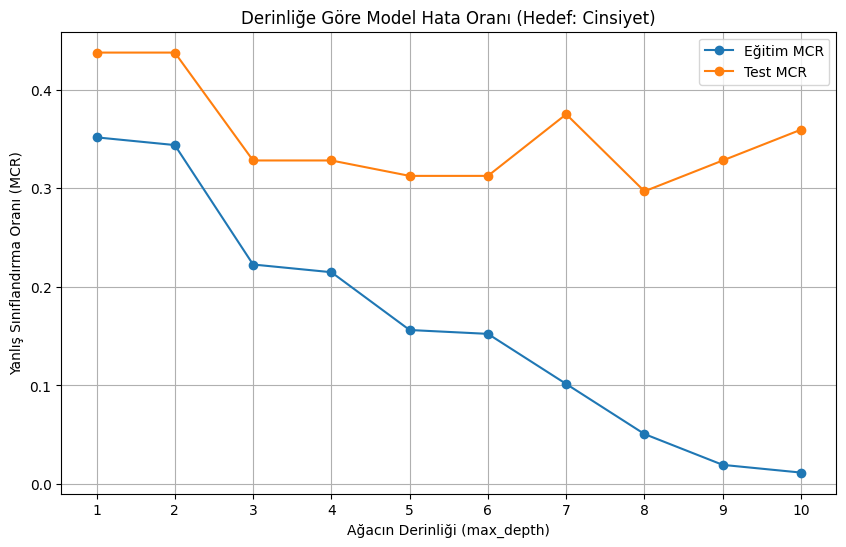

In [21]:
plt.figure(figsize=(10, 6))
plt.plot(derinlikler, egitim_mcr, marker='o', label='Eğitim MCR')
plt.plot(derinlikler, test_mcr, marker='o', label='Test MCR')
plt.xlabel('Ağacın Derinliği (max_depth)')
plt.ylabel('Yanlış Sınıflandırma Oranı (MCR)')
plt.title('Derinliğe Göre Model Hata Oranı (Hedef: Cinsiyet)')
plt.legend()
plt.grid(True)
plt.xticks(derinlikler)
plt.show()

In [22]:
optimum_derinlik_cinsiyet = 3

final_agac_cinsiyet = DecisionTreeClassifier(max_depth=optimum_derinlik_cinsiyet, random_state=42)
final_agac_cinsiyet.fit(X_egitim, y_egitim)

# Test verisinin MCR’si
y_tahmin_cinsiyet = final_agac_cinsiyet.predict(X_test)
test_mcr_cinsiyet = 1 - accuracy_score(y_test, y_tahmin_cinsiyet)
print(f'Optimum Derinlik (Cinsiyet): {optimum_derinlik_cinsiyet}')
print(f'Test Hatası (MCR) (Cinsiyet): {test_mcr_cinsiyet:.4f}')

Optimum Derinlik (Cinsiyet): 3
Test Hatası (MCR) (Cinsiyet): 0.3281


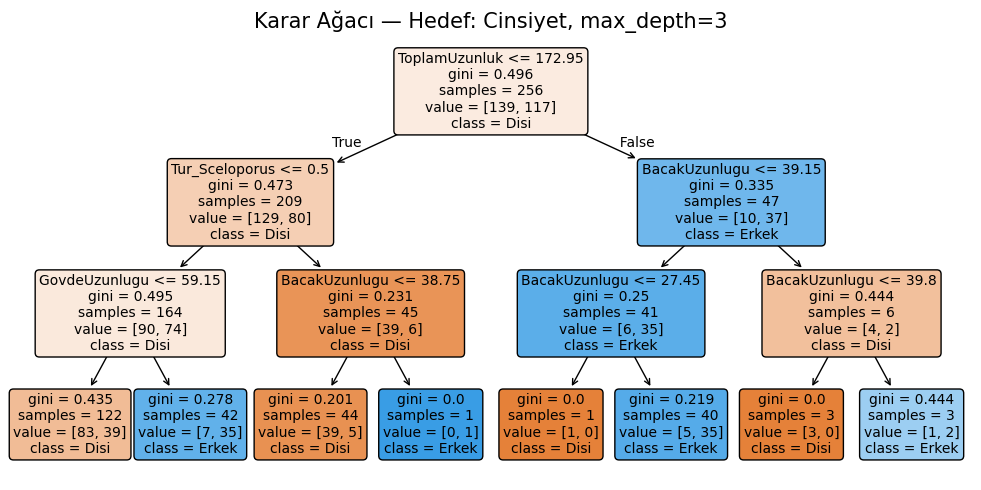

In [23]:
plt.figure(figsize=(10, 5))
plot_tree(
    final_agac_cinsiyet,
    feature_names=X.columns.tolist(),
    class_names=list(final_agac_cinsiyet.classes_.astype(str)), # sınıf isimlerini metne çevirir
    filled=True,
    rounded=True,
    fontsize=10 # Yazı boyutunu ayarlandı
)
plt.title(f'Karar Ağacı — Hedef: {hedef_degisken}, max_depth={optimum_derinlik_cinsiyet}', fontsize=15)
plt.tight_layout()
plt.show()


Üçüncü karar ağacımızı `Tur` hedef değişkeni

---

In [24]:
hedef_degisken = 'Tur'
ozellikler = [col for col in df.columns if col != hedef_degisken]


y = df[hedef_degisken]


X = pd.get_dummies(df[ozellikler], drop_first=True)


display(X.head())

,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu,Cinsiyet_Erkek,YasamAlani_Kaya,YasamAlani_Yer
0,43.8,102.2,5.18,21.6,False,False,True
1,62.1,149.8,16.78,29.7,False,True,False
2,37.6,76.4,4.94,18.5,False,False,True
3,70.4,170.4,18.23,28.4,True,False,True
4,52.7,137.9,8.60,25.8,False,False,False



İkinci karar ağacımızı `Tur` hedef değişkeni

In [25]:
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)



In [26]:
print('Eğitim seti:', len(X_egitim), 'kertenkele')
print('Test seti:  ', len(X_test),   'kertenkele')
print()
print('Eğitim seti sınıf dağılımı:')
print(y_egitim.value_counts())
print('\nTest seti sınıf dağılımı:')
print(y_test.value_counts())

Eğitim seti: 256 kertenkele
Test seti:   64 kertenkele

Eğitim seti sınıf dağılımı:
Tur
Anolis        107
Sceloporus     87
Uta            62
Name: count, dtype: int64

Test seti sınıf dağılımı:
Tur
Anolis        26
Sceloporus    22
Uta           16
Name: count, dtype: int64


In [27]:
derinlikler = list(range(1, 11))

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim, y_egitim)

    egitim_mcr = 1 - accuracy_score(y_egitim, agac.predict(X_egitim))
    test_mcr = 1 - accuracy_score(y_test, agac.predict(X_test))

    print(f"{derinlik:>10} {egitim_mcr:>12.3f} {test_mcr:>10.3f}")

         1        0.266      0.281
         2        0.191      0.219
         3        0.184      0.203
         4        0.137      0.281
         5        0.102      0.203
         6        0.078      0.250
         7        0.031      0.219
         8        0.020      0.234
         9        0.000      0.250
        10        0.000      0.250


In [28]:
egitim_mcr = []
test_mcr = []

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim,y_egitim)
    egitim_mcr.append(1 - accuracy_score(y_egitim, agac.predict(X_egitim)))
    test_mcr.append(  1 - accuracy_score(y_test,agac.predict(X_test)))



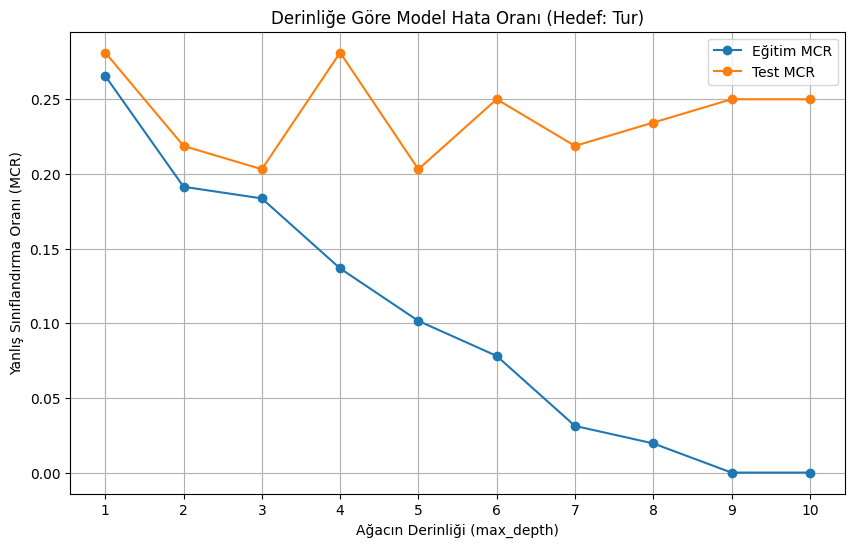

In [29]:
plt.figure(figsize=(10, 6))
plt.plot(derinlikler, egitim_mcr, marker='o', label='Eğitim MCR')
plt.plot(derinlikler, test_mcr, marker='o', label='Test MCR')
plt.xlabel('Ağacın Derinliği (max_depth)')
plt.ylabel('Yanlış Sınıflandırma Oranı (MCR)')
plt.title('Derinliğe Göre Model Hata Oranı (Hedef: Tur)')
plt.legend()
plt.grid(True)
plt.xticks(derinlikler)
plt.show()

**4)Kurduğunuz her karar ağacı için bu grafiği ayrı ayrı çizin. Optimum derinlik her hedef için aynı mı çıktı? Farklılaştıysa neden?** 3 karar ağacı için ayrı ayrı çizildi. Optimum derinlik farklı hedef değişkenler için farklı çıktı. Hedef değişkenlerinin verilerdeki durumu farklıdır. Bazı veriler düşük sayıda dal ile çözüme ulaştırırken bazıları daha fazla derinliğe ihtiyaç duyar.

In [30]:
optimum_derinlik_tur = 3

final_agac_tur = DecisionTreeClassifier(max_depth=optimum_derinlik_tur, random_state=42)
final_agac_tur.fit(X_egitim, y_egitim)



DecisionTreeClassifier(max_depth=3, random_state=42)

In [31]:

y_tahmin_tur = final_agac_tur.predict(X_test)
test_mcr_tur = 1 - accuracy_score(y_test, y_tahmin_tur)
print(f'Optimum Derinlik (Tur): {optimum_derinlik_tur}')
print(f'Test Hatası (MCR) (Tur): {test_mcr_tur:.4f}')

Optimum Derinlik (Tur): 3
Test Hatası (MCR) (Tur): 0.2031


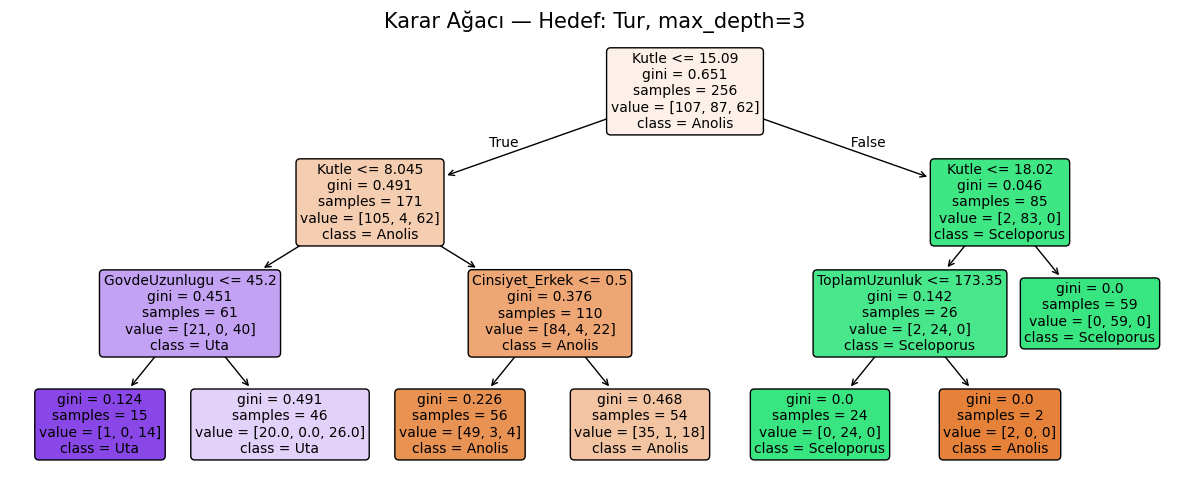

In [32]:
plt.figure(figsize=(12, 5))
plot_tree(
    final_agac_tur,
    feature_names=X.columns.tolist(),
    class_names=list(final_agac_tur.classes_.astype(str)),
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title(f'Karar Ağacı — Hedef: {hedef_degisken}, max_depth={optimum_derinlik_tur}', fontsize=15)
plt.tight_layout()
plt.show()

**3)Aynı veri, farklı bir hedef değişkenle (örneğin YasamAlani yerine Tur) çalıştırıldığında kök düğüm değişti mi? Değiştiyse bunu nasıl yorumlarsınız? Son hedef değişkenden sonra cevaplanacaktır.**

cevap: Evet, kök düğüm değişecektir. Makine öğrenmesinde değişkenlerin önemi, hedef değişkenle olan ilişkilerine göre belirlenir. Her hedefin diğer değişkenlerle ilişkisi farklıdır. Kök düğüm seçilirken veriyi en iyi şekilde bölen değişken seçilir. Bu nedenle hedef değiştiğinde kök düğüm de değişir.

### Soru 1 — Öğrenme Yolculuğu

Bu dönemde data kartları, CODAP ve Python olmak üzere üç farklı ortamda karar ağacı oluşturdunuz. Aşağıdaki soruları bu ortamları göz önünde bulundurarak yanıtlayın:  

1.  **Her ortam size farklı bir şey kattı mı? Her bir ortamın neler kattığını yazın.**
    *Cevap: [Evet, her ortam farklı katkılar sağladı. Data kartları karar ağacının mantığını somut olarak görmemi ve karar verme sürecini adım adım anlamamı sağladı.]

2.  **Hangi ortamda "modelim ne yapıyor" sorusunu daha iyi anladınız? Nedeninizi açıklayın.**
    *Cevap: [Modelin ne yaptığını en iyi Codap ortamında anladım. Çünkü karar ağacının nasıl dallandığını ve verileri hangi kurallara göre ayırdığını görsel olarak takip edebildim. Bu sayede modelin karar verme sürecini daha net kavradım.]*

3.  **Hangi ortam size daha kolay geldi? Bu kolaylık gerçekten anladığınızı mı, yoksa sadece alıştığınızı mı gösteriyor? Nedeninizi açıklayın.**
    *Cevap: [Bana en kolay gelen ortam Codap oldu. Görsel bir yapıya sahip olduğu için ağacın oluşumunu takip etmek daha rahattı. Ancak bu kolaylık sadece alışkanlıktan değil, karar ağacının mantığını daha açık göstermesinden kaynaklanıyordu]*

4.  **Hangi ortamda en çok zorlandınız ve bu zorluk neden kaynaklanıyordu? Aracın kendisi mi, yoksa karar ağacı kavramının o ortamda daha mı görünmez olması mıydı? Nedeninizi açıklayın.**
    *Cevap: [En çok colap ortamında zorlandım. Çünkü  kodları doğru yazmak ve çıktıları yorumlamak dikkat gerektiriyordu. Ayrıca karar ağacının yapısı doğrudan görünmediği için modelin nasıl çalıştığını anlamak diğer ortamlara göre daha zordu.]*
    

5.  **Yaptığınız bir hatayı hangi ortamda daha kolay fark ettiniz? Sizi uyaran şey aracın kendisi miydi, yoksa başka bir şey mi?**
    *Cevap: [Hatalarımı en kolay colab ortamında fark ettim. Çünkü elde ettiğim hata oranları ve performans değerleri beklediğim sonuçlardan farklı çıktığında bir sorun olduğunda hata veriyordu ve çalışmıyordu.]*

6.  **Bir ortamda rahatlıkla yapabildiğiniz ama bir diğerinde hiç yapamadığınız bir şey oldu mu?**
    *Cevap: [Evet. colab farklı derinlik değerlerini deneyerek eğitim ve test hatalarını ayrıntılı şekilde karşılaştırabildim. Bunu diğer ortamlarda ayrıntılı göremedim.]*

7.  **Üç ortamdan birinin diğerinin yerini tutamayacağı bir durum var mı? Nedeninizi açıklayın.**
    *Cevap: [Evet. colabın model performansını ayrıntılı olarak analiz etmek için gerekliydi ancak karar ağacının mantığını ilk kez öğrenmek için tek başına yeterli değildi. diğerleri ise veri analizi için yeterli detay veremiyordu. Bu nedenle birbirlerinin yerini tutamazlar]*

Veri Anlayışı soruları
Kertenkele verisindeki üç yaşam alanı (Yer / Kaya / Ağaç) ile fiziksel özellikler arasındaki ilişkiyi düşünün:

**1)Modelinizin kök düğümde seçtiği değişken sizi şaşırttı mı? Biyolojik açıdan bu seçim mantıklı mı? Cevap:** [hayır şaşırtmadı. Biyolojik açıdan bakıldığında da bu değişkenin yaşam alanıyla ilişkili olması mantıklı geldi Bu nedenle modelin yaptığı seçim biyolojik beklentilerle uyumludur.]

**2)Ağaçta yaşayan bir kertenkelenin yerde yaşayandan fiziksel olarak farklı olmasını bekler miydiniz? Modeliniz bu farkı yakalayabildi mi? Cevap:** [Evet, farklı yaşam alanlarında yaşayan kertenkelelerin fiziksel özelliklerinde bazı farklılıklar olmasını beklerdim. Örneğin ağaçta yaşayan türlerin tutunma veya tırmanma gibi kabiliyeti artıracak özelliklerin olması gerekir. Model de kullandığı değişkenler aracılığıyla bu farklılıkları büyük ölçüde yakalayabilmiş ve yaşam alanlarını ayırt edebilmiştir.]

**3)Modelinizin yanlış sınıflandırdığı bireyler hangi yaşam alanına aitti? Bunun biyolojik bir açıklaması olabilir mi? Cevap:** [Cevap: Yanlış sınıflandırılan bireyler genellikle özellikleri iki yaşam alanı arasında benzerlik gösteren bireylerdi. Bunun biyolojik bir açıklaması olabilir. Bazı kertenkeleler yaşadıkları ortama tam uyum sağlamamış olabilir ya da fiziksel özellikleri diğer yaşam alanındaki bireylerle benzerlik gösterebilir. Bu durum modelin sınıflandırma yaparken hata yapmasına neden olmuş olabilir.]

**4)Veriyi ilk gördüğünüzde kendiniz hangi değişkenin en belirleyici olacağını tahmin etmiştiniz? Modelinizin bulgusuyla örtüştü mü? Cevap:** [Veriyi ilk gördüğümde en belirleyici değişkenin vücut yapısıyla veya hareket kabiliyetiyle ilişkili bir özellik olacağını düşünmüştüm. Modelin seçtiği değişken bu tahminimle büyük ölçüde örtüştü ve yaşam alanlarını ayırt etmede gerçekten etkili bir özellik olduğunu gösterdi.]


** Model Performansı soruları**

**Seçtiğiniz optimum derinlikte elde ettiğiniz MCR değerini yazın ve gerekçelendirerek yanıtlayın:** mcr değerini 0.3281 olarak buldum. 0.3281 değeri, modelin genelleme performansının en iyi olduğu noktayı temsil etmektedir. Derinlik daha fazla artırıldığında model overfitting yapmaya başlayacağından test hatası artmakta, daha düşük derinliklerde ise verideki önemli örüntüler yeterince öğrenilememektedir.

**Hangi sınıf en iyi, hangisi en kötü tahmin edildi? Bunun bir açıklaması var mı? Cevap:** [Cevap: Model, fiziksel özellikleri diğer sınıflardan daha belirgin olan yaşam alanını daha başarılı tahmin etti. En düşük başarı ise özellikleri diğer sınıflarla daha fazla benzerlik gösteren yaşam alanında görüldü. Bunun nedeni bazı bireylerin fiziksel özelliklerinin birbirine yakın olması ve sınıflar arasındaki sınırların net olmamasıdır.]

**MCR değeriniz sizi tatmin etti mi? "İyi" bir model için bu değerin ne olması gerektiğini düşünüyorsunuz? Cevap:** [Cevap: Elde ettiğim MCR değeri genel olarak tatmin ediciydi çünkü model test verilerinin büyük kısmını doğru sınıflandırabildi. Bir modelin iyi kabul edilebilmesi için MCR değerinin mümkün olduğunca düşük olması gerekir. ]

**Aynı veriyle farklı bir hedef değişken seçseydiniz (Tur ya da Cinsiyet) MCR değeri değişir miydi? Değiştiyse neden? (Bu soruyu diğer iki karar ağacını oluşturduktan sonra yanıtlayın.) Cevap:** [Evet, değişebilirdi. Çünkü bazı hedef değişkenler fiziksel özelliklerle daha güçlü ilişkilere sahipken bazıları daha zayıf ilişkilere sahip olabilir. Eğer seçilen hedef değişken veri içerisindeki diğer özelliklerle daha kolay ayırt edilebiliyorsa MCR değeri düşer, aksi durumda ise yükselir.]

Modelin başarısız olduğu durumlar size veri hakkında ne söylüyor? Cevap: [Cevap: Modelin hata yaptığı durumlar, veri içerisindeki bazı bireylerin özelliklerinin birbirine çok benzediğini gösteriyor. Ayrıca yaşam alanları arasında tamamen kesin sınırlar olmadığını ve bazı bireylerin birden fazla sınıfın özelliklerini taşıyabildiğini düşündürüyor. Bu durum verinin karmaşık yapısını ve modelin karşılaştığı zorlukları ortaya koymaktadır.]

**Karar Ağaçlarının Sınırları soruları**

**Bu ödevde karar ağacının her zaman mükemmel çalışmadığını gördünüz:**


**1)Modelinizin hata yaptığı durumlar rastgele mi görünüyor, yoksa belirli bir örüntü var mı? Cevap:** [Hatalar tamamen rastgele görünmüyor. Model genellikle fiziksel özellikleri birbirine benzeyen veya farklı sınıflar arasında kalan bireyleri yanlış sınıflandırdı. Bu durum, veri içinde belirli bir örüntü bulunduğunu ve modelin özellikle benzer özelliklere sahip bireyleri ayırt etmekte zorlandığını gösteriyor.]

**2)Bu modelin daha iyi sonuç verebilmesi için neler yapılabilir? Yalnızca teknik değil, verinin kendisiyle ilgili ne değişebilir? Cevap:** [Modelin başarısını artırmak için daha fazla veri kullanılabilir ve yaşam alanlarını daha iyi açıklayan yeni değişkenler eklenebilir. Ayrıca eksik veya hatalı verilerin düzeltilmesi de performansı artırabilir. Teknik açıdan ise farklı derinlikler denenebilir veya budama yöntemleri kullanılarak overfitting önlenebilir.]

**3)Karar ağacı yerine farklı bir model kullansaydınız sonuç değişir miydi? Neden? Cevap:** [Cevap: Evet, sonuçlar değişebilirdi. Karar ağaçları basit ve yorumlanabilir modellerdir ancak karmaşık ilişkileri her zaman yeterince iyi öğrenemeyebilirler. Birden fazla ağacın birlikte çalıştığı modeller kullanılsaydı daha düşük hata oranları elde etmek mümkün olabilirdi.]

**4)Bu deneyimden sonra bir arkadaşınıza "karar ağacı nedir, ne işe yarar, nerede yetersiz kalır?" diye sorsalar ne söylerdiniz? Cevap:** [Cevap: Karar ağacı, verileri belirli kurallara göre dallara ayırarak tahmin yapan bir makine öğrenmesi modelidir. Hangi özelliklerin karar vermede etkili olduğunu açıkça göstermesi en büyük avantajlarından biridir. Ancak veri karmaşıklaştığında veya sınıflar arasında net farklar bulunmadığında hata yapabilir. Ayrıca ağacın derinliği gereğinden fazla artırılırsa veriyi ezberleyerek yeni veriler üzerinde başarısız sonuçlar verebilir.]